# Level-Set Active Contours

Represent a moving contour as the zero level of a function and evolve that function on a grid. Compare geometric and region-based forces, and examine how redistancing helps maintain a usable level-set representation.


## Run this tour

Run the cells in order with a Python 3 kernel. The first cell locates the companion data and toolbox and installs missing dependencies when needed. All worked examples include their implementation directly in this notebook. Random seeds make comparisons reproducible; you can change them to explore other samples.


In [1]:
# Locate the companion toolbox locally, or fetch it for a standalone/Colab copy.
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

working = Path.cwd()
candidates = [working, working / "python", working.parent / "python"]
python_dir = next((p for p in candidates if (p / "nt_toolbox").is_dir()), None)
if python_dir is None:
    checkout = working / "numerical-tours-support"
    if not checkout.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                "master",
                "https://github.com/gpeyre/numerical-tours.git",
                str(checkout),
            ],
            check=True,
        )
    python_dir = checkout / "python"
os.chdir(python_dir)
if str(python_dir) not in sys.path:
    sys.path.insert(0, str(python_dir))
requirements = python_dir / "requirements.txt"
if any(
    importlib.util.find_spec(name) is None
    for name in [
        "numpy",
        "scipy",
        "matplotlib",
        "skimage",
        "sklearn",
        "pywt",
        "ipywidgets",
        "cvxpy",
        "skfmm",
        "autograd",
        "progressbar",
        "celer",
    ]
):
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-r", str(requirements)], check=True
    )

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
plt.rcParams.update(
    {
        "figure.figsize": (8, 4),
        "figure.dpi": 100,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 11,
        "image.cmap": "gray",
    }
)
%matplotlib inline


$\newcommand{\dotp}[2]{\langle #1, #2 \rangle}$
$\newcommand{\enscond}[2]{\lbrace #1, #2 \rbrace}$
$\newcommand{\pd}[2]{ \frac{ \partial #1}{\partial #2} }$
$\newcommand{\umin}[1]{\underset{#1}{\min}\;}$
$\newcommand{\umax}[1]{\underset{#1}{\max}\;}$
$\newcommand{\uargmin}[1]{\underset{#1}{argmin}\;}$
$\newcommand{\norm}[1]{\|#1\|}$
$\newcommand{\abs}[1]{\left|#1\right|}$
$\newcommand{\choice}[1]{ \left\{  \begin{array}{l} #1 \end{array} \right. }$
$\newcommand{\pa}[1]{\left(#1\right)}$
$\newcommand{\diag}[1]{{diag}\left( #1 \right)}$
$\newcommand{\qandq}{\quad\text{and}\quad}$
$\newcommand{\qwhereq}{\quad\text{where}\quad}$
$\newcommand{\qifq}{ \quad \text{if} \quad }$
$\newcommand{\qarrq}{ \quad \Longrightarrow \quad }$
$\newcommand{\ZZ}{\mathbb{Z}}$
$\newcommand{\CC}{\mathbb{C}}$
$\newcommand{\RR}{\mathbb{R}}$
$\newcommand{\EE}{\mathbb{E}}$
$\newcommand{\Zz}{\mathcal{Z}}$
$\newcommand{\Ww}{\mathcal{W}}$
$\newcommand{\Vv}{\mathcal{V}}$
$\newcommand{\Nn}{\mathcal{N}}$
$\newcommand{\NN}{\mathcal{N}}$
$\newcommand{\Hh}{\mathcal{H}}$
$\newcommand{\Bb}{\mathcal{B}}$
$\newcommand{\Ee}{\mathcal{E}}$
$\newcommand{\Cc}{\mathcal{C}}$
$\newcommand{\Gg}{\mathcal{G}}$
$\newcommand{\Ss}{\mathcal{S}}$
$\newcommand{\Pp}{\mathcal{P}}$
$\newcommand{\Ff}{\mathcal{F}}$
$\newcommand{\Xx}{\mathcal{X}}$
$\newcommand{\Mm}{\mathcal{M}}$
$\newcommand{\Ii}{\mathcal{I}}$
$\newcommand{\Dd}{\mathcal{D}}$
$\newcommand{\Ll}{\mathcal{L}}$
$\newcommand{\Tt}{\mathcal{T}}$
$\newcommand{\si}{\sigma}$
$\newcommand{\al}{\alpha}$
$\newcommand{\la}{\lambda}$
$\newcommand{\ga}{\gamma}$
$\newcommand{\Ga}{\Gamma}$
$\newcommand{\La}{\Lambda}$
$\newcommand{\Si}{\Sigma}$
$\newcommand{\be}{\beta}$
$\newcommand{\de}{\delta}$
$\newcommand{\De}{\Delta}$
$\newcommand{\phi}{\varphi}$
$\newcommand{\th}{\theta}$
$\newcommand{\om}{\omega}$
$\newcommand{\Om}{\Omega}$


This tour explores image segementation using level set methods.


In [2]:
import numpy as np
import scipy as scp
import pylab as pyl
import matplotlib.pyplot as plt

from nt_toolbox.general import np, plt, pylab, rescale
from nt_toolbox.signal import div, grad, imageplot, load_image, np, plt, pylab

import warnings

%matplotlib inline

Managing level set functions
----------------------------
In the level set formalism, the evolution of some curve $ (\ga(t))_{t=0}^1 $
is computed by evolving the
zero level of a function $\phi : \RR^2 \rightarrow \RR $
$$ \enscond{\ga(s)}{ s \in [0,1] } = \enscond{x \in \RR^2}{\phi(x)=0}. $$
This corresponds to replacing the parameteric representation $\ga$ of
the curve by an implicit representation. This requires an additional
dimension (and hence more storage) but ease the handling of topological
change of the curve during the evolution.


Discretazion size $n \times n$ of the domain $[0,1]^2$.


In [3]:
n = 200
Y, X = np.meshgrid(np.arange(1, n + 1), np.arange(1, n + 1))

One can create a circular shape by using the signed distance function to
a circle
$$ \phi_1(x) = \sqrt{ (x_1-c_1)^2 + (x_2-c_2)^2 } - r $$
where $r>0$ is the radius and $c \in \RR^2$ the center.


Radius $r$.


In [4]:
r = n / 3.0

Center $c$.


In [5]:
c = np.array([r, r]) + 10

Distance function $\phi_1$.


In [6]:
phi1 = np.sqrt((X - c[0]) ** 2 + (Y - c[1]) ** 2) - r

__Worked example 1__

Load a square shape $\phi_2$ at a different position for the center.


In [7]:
r = n / 3.0
c = n - 10 - np.array([r, r])
phi2 = np.maximum(abs(X - c[0]), abs(Y - c[1])) - r

Display the curves associated to $\phi_1$ and $\phi_2$.


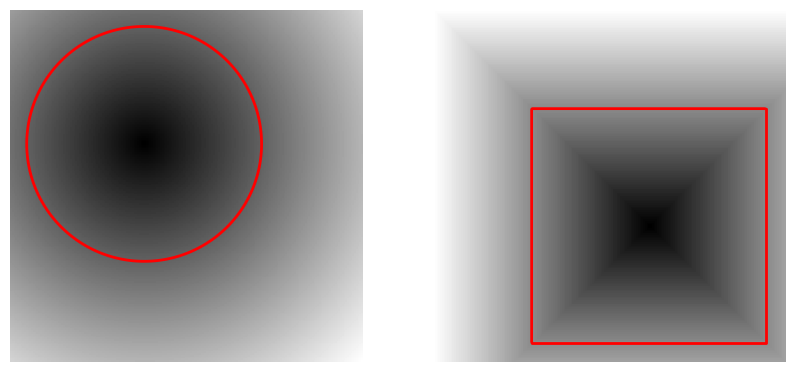

In [8]:
from nt_toolbox.plot_levelset import imageplot, np, plot_levelset, plt

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plot_levelset(phi1)

plt.subplot(1, 2, 2)
plot_levelset(phi2)

__Worked example 2__

Compute the intersection and the union of the two shapes.
Store the union in $\phi_0$ (phi0)
that we will use in the remaining part of the tour.


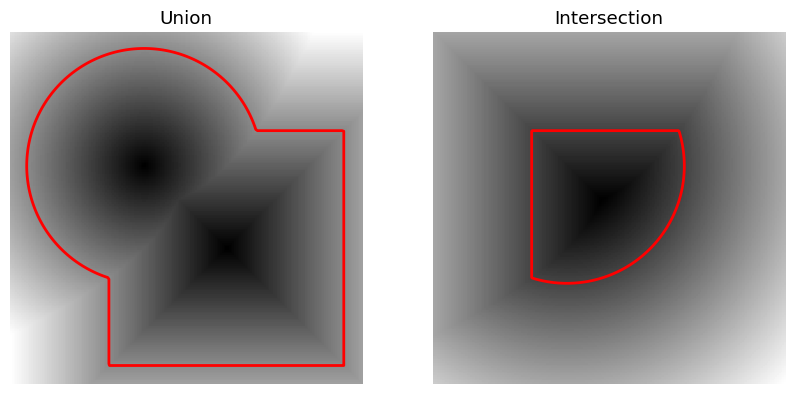

In [9]:
plt.figure(figsize=(10, 5))
phi0 = np.minimum(phi1, phi2)

plt.subplot(1, 2, 1)
plot_levelset(phi0)
plt.title("Union")

plt.subplot(1, 2, 2)
plot_levelset(np.maximum(phi1, phi2))
plt.title("Intersection")

plt.show()

Mean Curvature Motion.
----------------------
The mean curvature motion corresponds to the minimizing flow of the
length of the curve
$$ \int_0^1 \norm{\ga'(s)} d s. $$



It is implemeted in a level set formalism by a familly $\phi_t$ of
level set function parameterized by an artificial time $t \geq 0$, that
satisfies the following PDE
$$ \pd{\phi_t}{t} = -G(\phi_t)
  \qwhereq G(\phi) = -\norm{\nabla \phi} \text{div}
      \pa{  \frac{\nabla \phi}{\norm{\nabla \phi}} }  $$
and where $\nabla \phi_t(x) \in \RR^2$ is the spacial gradient.


This flow is computed using a gradient descent
$\phi^{(0)} = \phi_0$ and
$$ \phi^{(\ell+1)} = \phi^{(\ell)} - \tau G(\phi^{(\ell)}), $$
where $\tau>0$ is small enough time step.


Maximum time of the evolution $0 \leq t \leq t_{\max}$.


In [10]:
Tmax = 200

Time step $\tau>0$ (should be small).


In [11]:
tau = 0.5

Number of iterations.


In [12]:
niter = int(Tmax / tau)

Initial shape $\phi^{(0)}$ at $t=0$.


In [13]:
phi = np.copy(phi0)

We now compute the right hand side of the evolution equation.


Compute the gradient $\nabla \phi$. We use centered differences for the discretization of the gradient.


In [14]:
from nt_toolbox.grad import grad, np

g0 = grad(phi, order=2)

Norm $\norm{\nabla \phi}$ of the gradient.


In [15]:
eps = np.finfo(float).eps
d = np.maximum(eps * np.ones([n, n]), np.sqrt(np.sum(g0**2, 2)))

Normalized gradient.


In [16]:
g = g0 / np.repeat(d[:, :, np.newaxis], 2, 2)

The curvature term.


In [17]:
from nt_toolbox.div import div, np

K = -d * div(g[:, :, 0], g[:, :, 1], order=2)

Perform one step of the gradient descent.


In [18]:
phi = phi - tau * K

__Worked example 3__

Implement the mean curvature motion.


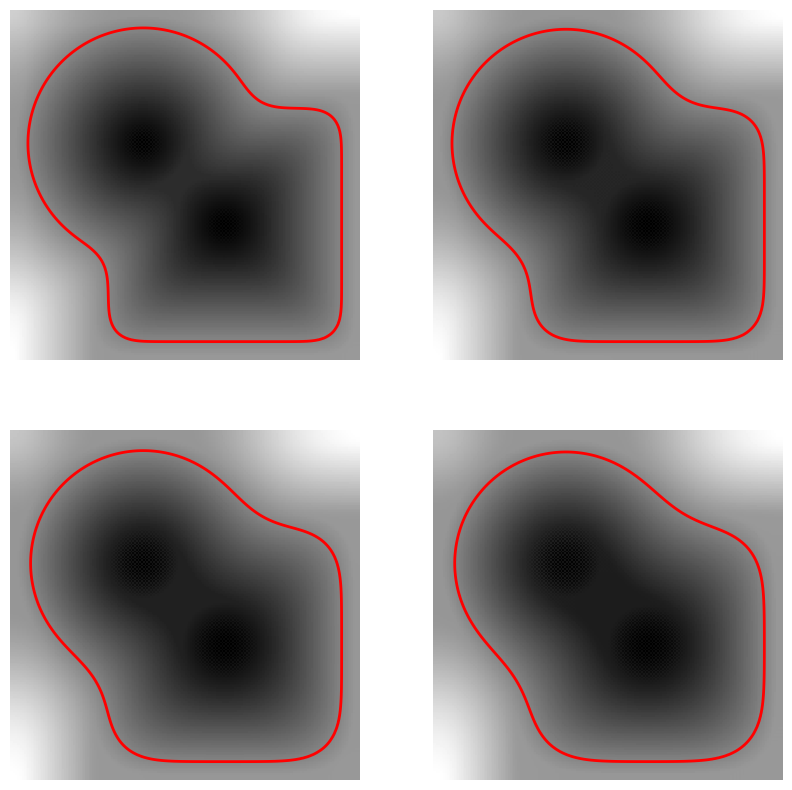

In [19]:
plt.figure(figsize=(10, 10))
phi = np.copy(phi0)  # initialization
eps = np.finfo(float).eps
k = 0

for i in range(1, niter + 1):
    g0 = grad(phi, order=2)
    d = np.maximum(eps * np.ones([n, n]), np.sqrt(np.sum(g0**2, 2)))
    g = g0 / np.repeat(d[:, :, np.newaxis], 2, 2)
    K = d * div(g[:, :, 0], g[:, :, 1], order=2)
    phi = phi + tau * K
    if i % int(niter / 4.0) == 0:
        k = k + 1
        plt.subplot(2, 2, k)
        plot_levelset(phi)

Levelset Re-distancing
----------------------
During PDE resolution, a level set function $\phi$ might become
ill-conditionned, so that the zero crossing is not sharp enough.
The quality of the level set function is restored by computing the
signed distance function to the zero level set.



This corresponds to first extracting the zero level set
$$ \Cc = \enscond{x \in \RR^2 }{\phi(x)=0},  $$
and then solving the following eikonal equation PDE on $\tilde \phi$
(in viscosity sense)
$$ \norm{\nabla \tilde \phi(x)} = 1
      \qandq \forall y \in \Cc, \tilde\phi(y)=0. $$
The one can replace $\phi$ by $\text{sign}(\phi(x))\tilde \phi(x)$
which is the signed distance function to $\Cc$.


We set $\phi=\phi_0^3$ so that they are both valid level set function
of the same curve, but $\phi$ is not the signed distance function.


In [20]:
phi = phi0**3

Solve the eikonal PDE using the Fast Marching algorithm. You have to install a C++ compiler (https://wiki.python.org/moin/WindowsCompilers#Microsoft_Visual_C.2B-.2B-_14.0_standalone:_Visual_C.2B-.2B-_Build_Tools_2015_.28x86.2C_x64.2C_ARM.29) and the package scikit-fmm (skfmm) to run this function (pip install scikit_fmm in the console).


In [21]:
from nt_toolbox.perform_redistancing import np, perform_redistancing

phi1 = perform_redistancing(phi0)

Display the level sets.


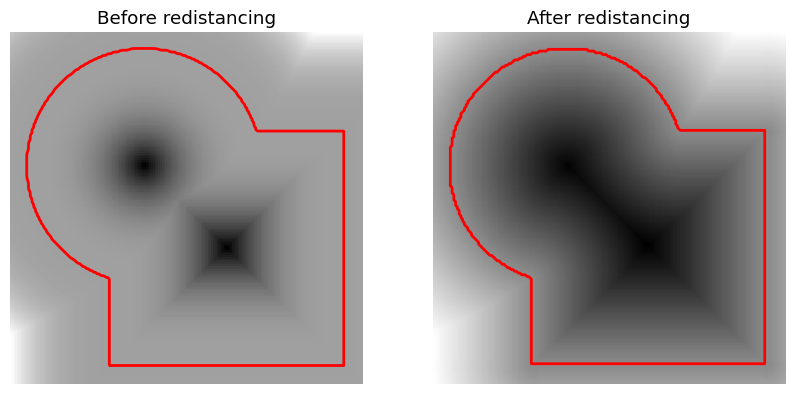

In [22]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plot_levelset(phi)
plt.title("Before redistancing")

plt.subplot(1, 2, 2)
plot_levelset(phi1)
plt.title("After redistancing")

plt.show()

Edge-based Segmentation with Geodesic Active Contour
----------------------------------------------------
Geodesic active contours compute loval minimum of a weighted geodesic
distance that attract the curve toward the features of the background
image.


_Note:_ these active contours should not be confounded with the geodesic shortest paths,
that are globally minimizing geodesics between two points.
Here the active contour is a close curve progressively decreasing a
weighted geodesic length that is only a local minimum
(the global minimum would be a single point).


Size of the image.


In [23]:
n = 200

First we load an image $f_0 \in \RR^{n \times n}$ to segment.


In [24]:
f0 = rescale(load_image("nt_toolbox/data/cortex.bmp", n))

Given a background image $f_0$ to segment, one needs to compute
an edge-stopping function $W$.
It should be small in area of high gradient, and high in area of large gradient.


We use here
$$ W(x) = \al + \frac{\be}{\epsilon + d(x) }
      \qwhereq d = \norm{\nabla f_0} \star h_a, $$
and where $h_a$ is a blurring kernel of size $a>0$.


Compute the magnitude of the gradient $d_0(x) = \norm{\nabla f_0(x)}$.


In [25]:
g = grad(f0, order=2)
d0 = np.sqrt(np.sum(g**2, 2))

Blur size $a$.


In [26]:
a = 5

Compute the blurring $d = d_0 \star h_a$.


In [27]:
from nt_toolbox.perform_blurring import np, perform_blurring, pyl

d = perform_blurring(d0, np.asarray([a]), bound="per")

Parameter $\epsilon>0$.


In [28]:
epsilon = 1e-1

We set the $\al$ and $\be$ parameters to adjust the overall values of $W$
(equivalently we use the function rescale).


In [29]:
W = 1.0 / (epsilon + d)
W = rescale(-d, 0.1, 1)

Display it.


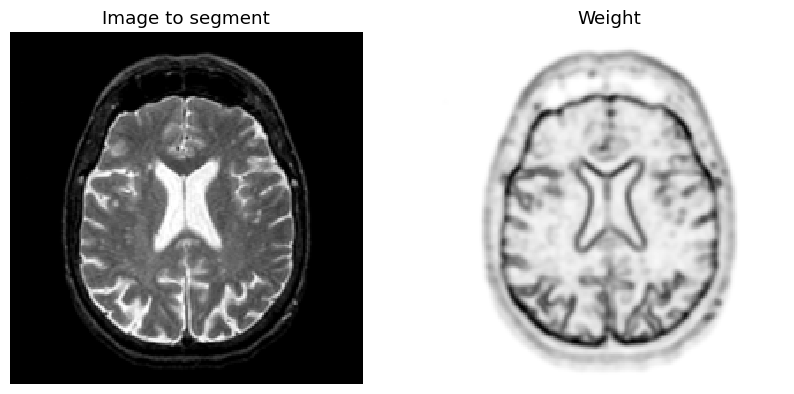

In [30]:
plt.figure(figsize=(10, 5))
imageplot(f0, "Image to segment", [1, 2, 1])
imageplot(W, "Weight", [1, 2, 2])

__Worked example 4__

Compute an initial shape $\phi_0$ at time $t=0$,
for instance a centered square.


In [31]:
Y, X = np.meshgrid(np.arange(1, n + 1), np.arange(1, n + 1))
r = n / 3.0
c = np.asarray([n, n]) / 2
phi0 = np.maximum(abs(X - c[0]), abs(Y - c[1])) - r

Display it.


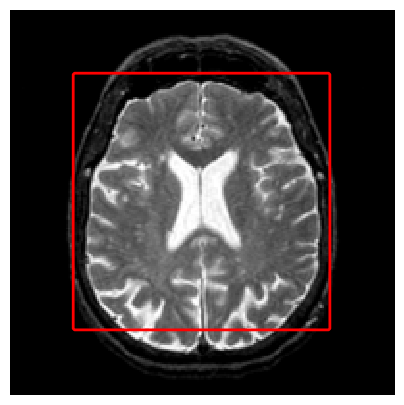

In [32]:
plt.figure(figsize=(5, 5))
plot_levelset(phi0, 0, f0)

The geodesic active contour minimizes a weighted length of curve
$$ \umin{\ga} \int_0^1 \norm{\ga'(s)} W(\ga(s)) d s $$


The level set implementation of the gradient descent of this energy reads
$$ \pd{\phi_t}{t} = G(\phi_t)
  \qwhereq G(\phi) = -\norm{\nabla \phi} \text{div}\pa{
          W \frac{\nabla \phi}{\norm{\nabla \phi}}
  } $$


This is implemented using a gradient descent scheme.
$$ \phi^{(\ell+1)} = \phi^{(\ell)} - \tau G(\phi^{(\ell)}), $$
where $\tau>0$ is small enough.


Gradient step size $\tau>0$.


In [33]:
tau = 0.4

Final time and number of iteration of the algorithm.


In [34]:
Tmax = 1500
niter = int(Tmax / tau)

Initial distance function $\phi^{(0)}=\phi_0$.


In [35]:
phi = np.copy(phi0)

Note that we can re-write the gradient of the energy as
$$ G(\phi) = -W \norm{\nabla \phi} \text{div} \pa{ \frac{\nabla \phi}{\norm{\nabla \phi}}  } - \dotp{\nabla W}{\nabla \phi} $$


Pre-compute once for all $\nabla W$.


In [36]:
gW = grad(W, order=2)

__Worked example 5__

Compute and store in G the gradient $G(\phi)$ (right hand side of the PDE)
using the current value of the distance function $\phi$.


In [37]:
gD = grad(phi, order=2)
d = np.maximum(eps * np.ones([n, n]), np.sqrt(np.sum(gD**2, 2)))
g = gD / np.repeat(d[:, :, np.newaxis], 2, 2)
G = -W * d * div(g[:, :, 0], g[:, :, 1], order=2) - np.sum(gW * gD, 2)

Do the descent step.


In [38]:
phi = phi - tau * G

Once in a while (e.g. every 30 iterations), perform re-distancing of $\phi$.


In [39]:
phi = perform_redistancing(phi)

__Worked example 6__

Implement the geodesic active contours gradient descent.
Do not forget to do the re-distancing.


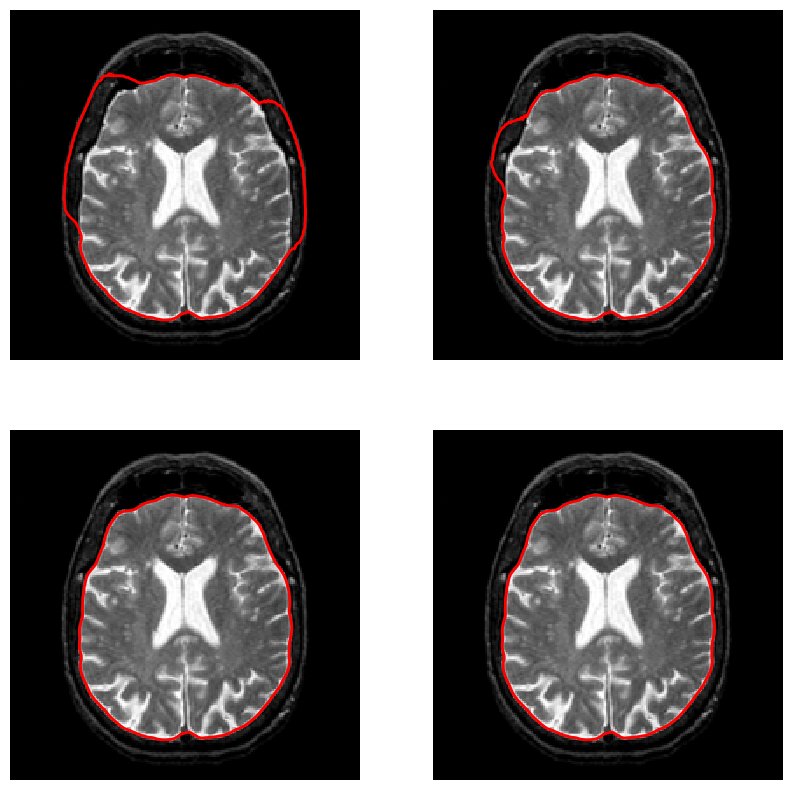

In [40]:
plt.figure(figsize=(10, 10))
phi = np.copy(phi0)
k = 0
gW = grad(W, order=2)

for i in range(1, niter + 1):
    gD = grad(phi, order=2)
    d = np.maximum(eps * np.ones([n, n]), np.sqrt(np.sum(gD**2, 2)))
    g = gD / np.repeat(d[:, :, np.newaxis], 2, 2)
    G = W * d * div(g[:, :, 0], g[:, :, 1], order=2) + np.sum(gW * gD, 2)
    phi = phi + tau * G
    if i % 30 == 0:
        phi = perform_redistancing(phi)
    if i % int(niter / 4.0) == 0:
        k = k + 1
        plt.subplot(2, 2, k)
        plot_levelset(phi, 0, f0)

Region-based Segmentation with Chan-Vese
-----------------------------------------
Chan-Vese active contours corresponds to a region-based energy
that looks for a piecewise constant approximation of the image.


The energy to be minimized is
$$ \umin{\phi}
      L(\phi) +
      \la \int_{\phi(x)>0} \abs{f_0(x)-c_1}^2 d x   +
      \la \int_{\phi(x)<0} \abs{f_0(x)-c_2}^2 d x
$$
where $L$ is the length of the zero level set of $\phi$.
Note that here $(c_1,c_2) \in \RR^2$ are assumed to be known.


__Worked example 7__

Compute an initial level set function $\phi_0$, stored in phi0,
for instance many small circles.


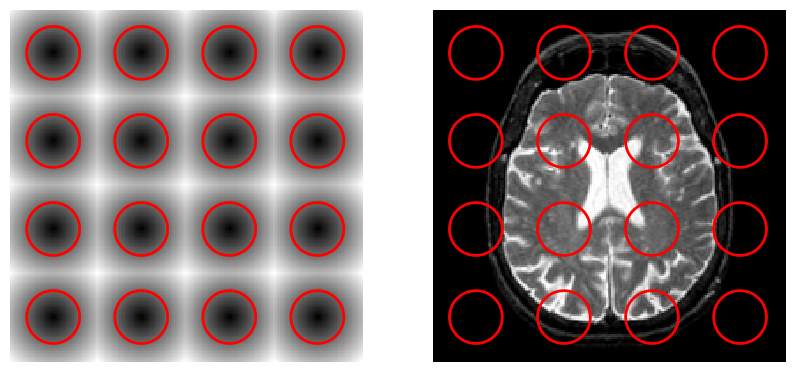

In [41]:
plt.figure(figsize=(10, 5))
Y, X = np.meshgrid(np.arange(1, n + 1), np.arange(1, n + 1))
k = 4  # number of circles
r = 0.3 * n / k
phi0 = np.zeros([n, n]) + float("inf")

for i in range(1, k + 1):
    for j in range(1, k + 1):
        c = (np.asarray([i, j]) - 1) * (n / k) + (n / k) * 0.5
        phi0 = np.minimum(phi0, np.sqrt(abs(X - c[0]) ** 2 + abs(Y - c[1]) ** 2) - r)

plt.subplot(1, 2, 1)
plot_levelset(phi0, 0)
plt.subplot(1, 2, 2)
plot_levelset(phi0, 0, f0)

Parameter $\la$


In [42]:
lambd = 2

Values for $c_1,c_2$


In [43]:
c1 = 0.7
c2 = 0

Step size.


In [44]:
tau = 0.5

Number of iterations.


In [45]:
Tmax = 100
niter = int(Tmax / tau)

Initial distance function $\phi_0$ at time $t=0$.


In [46]:
phi = np.copy(phi0)

The minimizing flow for the CV energy reads
$$ \pd{\phi_t}{t} = - G(\phi_t) $$
where
$$ G(\phi) =
- W \norm{\nabla \phi} \text{div}\pa{
	\frac{\nabla \phi}{\norm{\nabla \phi}}
} + \la (f_0-c_1)^2 - \la (f_0-c_2)^2. $$


__Worked example 8__

Compute this gradient $G(\phi)$ using the current value of the distance function
(phi$.
radient


In [47]:
gD = grad(phi, order=2)
d = np.maximum(eps * np.ones([n, n]), np.sqrt(np.sum(gD**2, 2)))
g = gD / np.repeat(d[:, :, np.newaxis], 2, 2)
G = (
    d * div(g[:, :, 0], g[:, :, 1], order=2)
    - lambd * (f0 - c1) ** 2
    + lambd * (f0 - c2) ** 2
)

Do a descent step.


In [48]:
phi = phi + tau * G

__Worked example 9__

Implement the full gradient descent.


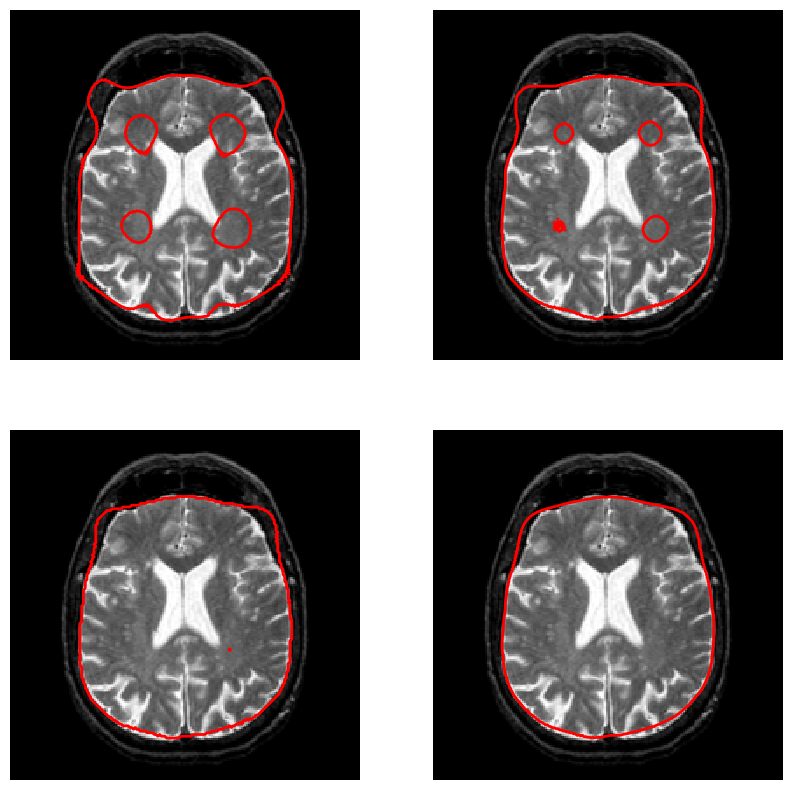

In [49]:
plt.figure(figsize=(10, 10))
phi = np.copy(phi0)
k = 0

for i in range(1, niter + 1):
    gD = grad(phi, order=2)
    d = np.maximum(eps * np.ones([n, n]), np.sqrt(np.sum(gD**2, 2)))
    g = gD / np.repeat(d[:, :, np.newaxis], 2, 2)
    G = (
        d * div(g[:, :, 0], g[:, :, 1], order=2)
        - lambd * (f0 - c1) ** 2
        + lambd * (f0 - c2) ** 2
    )
    phi = phi + tau * G
    if i % 30 == 0:
        phi = perform_redistancing(phi)
    if i % int(niter / 4.0) == 0:
        k = k + 1
        plt.subplot(2, 2, k)
        plot_levelset(phi, 0, f0)

## References and further reading

- John Canny. [A Computational Approach to Edge Detection](https://doi.org/10.1109/TPAMI.1986.4767851). 1986, IEEE Transactions on Pattern Analysis and Machine Intelligence 8(6), 679–698. Detection, localization, and nonmaximum suppression of edges.

- Michael Kass, Andrew Witkin, and Demetri Terzopoulos. [Snakes: Active Contour Models](https://doi.org/10.1007/BF00133570). 1988, International Journal of Computer Vision 1, 321–331. Parametric curves driven by regularization and image forces.

- Stanley Osher and James A. Sethian. [Fronts Propagating with Curvature-Dependent Speed: Algorithms Based on Hamilton–Jacobi Formulations](https://doi.org/10.1016/0021-9991(88)90002-2). 1988, Journal of Computational Physics 79(1), 12–49. Implicit front propagation using level-set functions.

- Tony F. Chan and Luminita A. Vese. [Active Contours Without Edges](https://doi.org/10.1109/83.902291). 2001, IEEE Transactions on Image Processing 10(2), 266–277. Region-based segmentation when image gradients are weak.

- Gabriel Peyré. [Advanced Signal, Image and Surface Processing](https://www.numerical-tours.com/book/AdvancedSignalProcessing.pdf). 2010, course notes. A mathematical companion to the Numerical Tours.
